In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=k_cvJa1kNaM___1_label_B4-0-0.mp4
/kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=m5zK-tzYCQM___1_label_B4-0-0.mp4
/kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=7isLhaNYgkU___1_label_B4-0-0.mp4
/kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=u0Tnw01PNxc___1_label_B4-0-0.mp4
/kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=ZCjNPgNu42g___1_label_B4-0-0.mp4
/kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=2WkuPNLfl5s___1_label_B4-0-0.mp4
/kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=Hnfy9XhlIPM___1_label_B4-0-0.mp4
/kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=v-Plzx73K68___1_label_B4-0-0.mp4
/kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=2al4t5inObA___1_label_B4-0-0.mp4
/kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=1io9Uh54Vhg___1_label_B4-0-0.mp4
/kaggle/input/datasets/bypktt/xd-violence/test/Riot/Riot_v=3zgaqeVSXuI___1_label

In [2]:
# Define the XD-Violence training and testing dataset paths used throughout the pipeline.
# Verify that both directories exist before proceeding with data loading and preprocessing.
import os
import cv2
import math
import random
import numpy as np
import pandas as pd

from pathlib import Path
from tqdm.auto import tqdm

TRAIN_ROOT = Path(
    "/kaggle/input/datasets/bypktt/xd-violence/train"
)

TEST_ROOT = Path(
    "/kaggle/input/datasets/bypktt/xd-violence/test"
)

print("Train:", TRAIN_ROOT)
print("Test :", TEST_ROOT)

print("\nTrain exists:", TRAIN_ROOT.exists())
print("Test exists :", TEST_ROOT.exists())

Train: /kaggle/input/datasets/bypktt/xd-violence/train
Test : /kaggle/input/datasets/bypktt/xd-violence/test

Train exists: True
Test exists : True


In [3]:
# class-selection and binary-label definition
ALL_CLASSES = [
    "Abuse",
    "CarAccident",
    "Explosion",
    "Fighting",
    "Normal",
    "Riot",
    "Shooting"
]

USED_CLASSES = [
    "CarAccident",
    "Explosion",
    "Fighting",
    "Normal",
    "Riot",
    "Shooting"
]

VIOLENCE_CLASSES = [
    "CarAccident",
    "Explosion",
    "Fighting",
    "Riot",
    "Shooting"
]

LABEL_MAP = {
    "Normal": 0,
    "CarAccident": 1,
    "Explosion": 1,
    "Fighting": 1,
    "Riot": 1,
    "Shooting": 1
}

print("Excluded:", "Abuse")
print("Used classes:", USED_CLASSES)
print("Violence classes:", VIOLENCE_CLASSES)

Excluded: Abuse
Used classes: ['CarAccident', 'Explosion', 'Fighting', 'Normal', 'Riot', 'Shooting']
Violence classes: ['CarAccident', 'Explosion', 'Fighting', 'Riot', 'Shooting']


In [4]:
# Converts the raw directory structure into a structured dataset manifest.
VIDEO_EXTENSIONS = {
    ".mp4",
    ".avi",
    ".mov",
    ".mkv",
    ".webm"
}


def collect_videos(root, split):

    records = []

    for class_name in USED_CLASSES:

        class_dir = root / class_name

        if not class_dir.exists():
            print(
                f"WARNING: missing directory: {class_dir}"
            )
            continue

        for video_path in class_dir.rglob("*"):

            if (
                video_path.is_file()
                and video_path.suffix.lower()
                in VIDEO_EXTENSIONS
            ):

                records.append({
                    "path": str(video_path),
                    "split": split,
                    "class": class_name,
                    "label": LABEL_MAP[class_name]
                })

    return records


train_records = collect_videos(
    TRAIN_ROOT,
    "train"
)

test_records = collect_videos(
    TEST_ROOT,
    "test"
)

records = train_records + test_records

df = pd.DataFrame(records)

print("Total videos:", len(df))
print("\nSplit:")
print(df["split"].value_counts())

print("\nClass:")
print(df["class"].value_counts())

print("\nBinary label:")
print(df["label"].value_counts())

Total videos: 4426

Split:
split
train    3680
test      746
Name: count, dtype: int64

Class:
class
Normal         2349
Fighting        484
Riot            473
CarAccident     468
Explosion       358
Shooting        294
Name: count, dtype: int64

Binary label:
label
0    2349
1    2077
Name: count, dtype: int64


In [5]:
# Extracts FPS, frame count and duration for every video
def get_video_metadata(path):

    cap = cv2.VideoCapture(path)

    if not cap.isOpened():
        return np.nan, np.nan, np.nan

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    frame_count = cap.get(
        cv2.CAP_PROP_FRAME_COUNT
    )

    duration = np.nan

    if (
        fps is not None
        and fps > 0
        and frame_count is not None
        and frame_count > 0
    ):
        duration = frame_count / fps

    cap.release()

    return duration, fps, frame_count


metadata = []

for path in tqdm(
    df["path"],
    desc="Reading video metadata"
):

    duration, fps, frame_count = (
        get_video_metadata(path)
    )

    metadata.append(
        (
            duration,
            fps,
            frame_count
        )
    )


df[
    [
        "duration",
        "fps",
        "frame_count"
    ]
] = pd.DataFrame(
    metadata,
    index=df.index
)

Reading video metadata:   0%|          | 0/4426 [00:00<?, ?it/s]

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x38394140] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x383ecb80] Referenced QT chapter track not found

In [6]:
# Detects videos with invalid metadata and removes unusable samples from the dataset.
before = len(df)

bad_metadata = (
    df["duration"].isna()
    | (df["duration"] <= 0)
    | df["fps"].isna()
    | (df["fps"] <= 0)
    | df["frame_count"].isna()
    | (df["frame_count"] <= 0)
)

print(
    "Videos with invalid metadata:",
    bad_metadata.sum()
)

if bad_metadata.sum() > 0:

    print(
        df.loc[
            bad_metadata,
            [
                "split",
                "class",
                "path"
            ]
        ].to_string(index=False)
    )

df = (
    df.loc[~bad_metadata]
    .reset_index(drop=True)
)

print(
    "\nVideos remaining:",
    len(df)
)

Videos with invalid metadata: 1
split  class                                                                                        path
train Normal /kaggle/input/datasets/bypktt/xd-violence/train/Normal/Normal_v=8cTqh9tMz_I___1_label_A.mp4

Videos remaining: 4425


In [7]:
WINDOW_SEC = 4.0
STRIDE_SEC = 2.0
FRAMES_PER_WINDOW = 16

IMG_SIZE = 112

In [8]:
def calculate_num_windows(duration):

    if (
        pd.isna(duration)
        or duration <= 0
    ):
        return 0

    if duration <= WINDOW_SEC:
        return 1

    return (
        int(
            np.floor(
                (duration - WINDOW_SEC)
                / STRIDE_SEC
            )
        )
        + 1
    )


df["num_windows"] = (
    df["duration"]
    .apply(calculate_num_windows)
)

print(
    df["num_windows"].describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

print("\nTotal windows:")
print(
    int(df["num_windows"].sum())
)

print("\nWindows by split:")
print(
    df.groupby("split")["num_windows"]
    .sum()
)

count    4425.000000
mean       83.119774
std       164.688949
min         1.000000
25%        29.000000
50%        52.000000
75%        89.000000
90%       160.000000
95%       209.800000
99%       573.360000
max      5407.000000
Name: num_windows, dtype: float64

Total windows:
367805

Windows by split:
split
test      45547
train    322258
Name: num_windows, dtype: int64


In [9]:
# cleaned dataset manifest to CSV
MANIFEST_PATH = (
    "/kaggle/working/"
    "xdviolence_clean_manifest.csv"
)

df.to_csv(
    MANIFEST_PATH,
    index=False
)

print(
    "Saved:",
    MANIFEST_PATH
)

Saved: /kaggle/working/xdviolence_clean_manifest.csv


In [10]:
# Displays the final dataset distribution, binary labels, durations and number of windows.
print("=" * 70)
print("FINAL DATASET")
print("=" * 70)

print("\nVideos:")
print(
    df.groupby(
        ["split", "class"]
    ).size()
)

print("\nBinary labels:")
print(
    df.groupby(
        ["split", "label"]
    ).size()
)

print("\nDuration:")
print(
    df["duration"].describe()
)

print("\nWindows:")
print(
    df["num_windows"].describe()
)

FINAL DATASET

Videos:
split  class      
test   CarAccident      93
       Explosion        85
       Fighting        107
       Normal          300
       Riot             99
       Shooting         62
train  CarAccident     375
       Explosion       273
       Fighting        377
       Normal         2048
       Riot            374
       Shooting        232
dtype: int64

Binary labels:
split  label
test   0         300
       1         446
train  0        2048
       1        1631
dtype: int64

Duration:
count     4425.000000
mean       168.896478
std        329.388223
min          1.416667
25%         60.000000
50%        107.083333
75%        180.125000
max      10816.208333
Name: duration, dtype: float64

Windows:
count    4425.000000
mean       83.119774
std       164.688949
min         1.000000
25%        29.000000
50%        52.000000
75%        89.000000
max      5407.000000
Name: num_windows, dtype: float64


In [11]:
df["source_id"] = (
    df["path"]
    .str.split("/")
    .str[-1]
    .str.split("___")
    .str[0]
)
print(df[["path", "source_id"]].head(20).to_string(index=False))

                                                                                                                            path                       source_id
      /kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_v=k7R_Qo-BiAw___00-06-10_00-07-19_label_B6-0-0.mp4       CarAccident_v=k7R_Qo-BiAw
      /kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_v=vhACO_m5pH0___00-22-42_00-24-10_label_B6-0-0.mp4       CarAccident_v=vhACO_m5pH0
      /kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_v=66F2bVUq_zk___00-00-00_00-00-51_label_B6-0-0.mp4       CarAccident_v=66F2bVUq_zk
/kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_Brick.Mansions.2014___00-40-15_00-40-55_label_B6-0-0.mp4 CarAccident_Brick.Mansions.2014
      /kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_v=nLAapCIlr-o___00-01-00_00-02-45_label_B6-0-0.mp4       CarAccident_v=nLAapCIlr-o
      /kaggle/input/datasets/bypkt

In [12]:
print(
    df.groupby("source_id")
      .size()
      .sort_values(ascending=False)
      .head(20)
)

source_id
Normal_v=vFPQ_NiDBIU                           32
Normal_Still.Walking.2008                      30
Normal_About.Time.2013                         29
Normal_Shoplifters.2018                        29
Normal_Be.with.You.2018                        29
Normal_The.Intouchables.2011                   29
Normal_Good.Will.Hunting.1997                  29
Normal_A.Beautiful.Mind.2001                   28
Normal_The.Pursuit.of.Happyness.2006           28
Normal_Love.Actually.2003                      27
Normal_The.Notebook.2004                       27
Normal_v=fkps18H3SXY                           27
Normal_Hear.Me.2009                            26
Normal_Before.Sunset.2004                      26
Normal_Your.Name.2016                          26
Normal_Flipped.2010                            25
Normal_Before.Sunrise.1995                     24
Normal_v=9eME1y6V-T4                           23
Normal_The.Secret.Life.of.Walter.Mitty.2013    22
Normal_One.Day.2011                     

In [13]:
# Defines the function that samples a fixed number of frames from a temporal video window.
def read_window_frames(
    video_path,
    start_sec,
    window_sec=WINDOW_SEC,
    num_frames=FRAMES_PER_WINDOW,
    img_size=IMG_SIZE
):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        raise RuntimeError(
            f"Could not open video: {video_path}"
        )

    fps = cap.get(
        cv2.CAP_PROP_FPS
    )

    if fps <= 0:
        cap.release()
        raise RuntimeError(
            f"Invalid FPS: {video_path}"
        )

    start_frame = int(
        start_sec * fps
    )

    end_frame = int(
        (start_sec + window_sec)
        * fps
    )

    frame_indices = np.linspace(
        start_frame,
        max(start_frame, end_frame - 1),
        num_frames
    ).astype(int)

    frames = []

    for frame_idx in frame_indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_idx)
        )

        ret, frame = cap.read()

        if not ret:
            continue

        frame = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2RGB
        )

        frame = cv2.resize(
            frame,
            (img_size, img_size)
        )

        frames.append(frame)

    cap.release()

    # Handle missing frames
    if len(frames) == 0:
        raise RuntimeError(
            f"No frames read: {video_path}"
        )

    while len(frames) < num_frames:
        frames.append(
            frames[-1].copy()
        )

    frames = frames[:num_frames]

    return np.stack(frames)

In [14]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import models, transforms

print("PyTorch:", torch.__version__)

print(
    "GPU count:",
    torch.cuda.device_count()
)

for i in range(torch.cuda.device_count()):
    print(
        i,
        torch.cuda.get_device_name(i)
    )

PyTorch: 2.10.0+cu128
GPU count: 2
0 Tesla T4
1 Tesla T4


In [15]:
# Loads the pretrained ResNet-18 weights and creates the corresponding preprocessing transformations for input frames.
weights = (
    models.ResNet18_Weights.DEFAULT
)

preprocess = (
    weights.transforms()
)

In [16]:
class ViolenceWindowDataset(Dataset):

    def __init__(
        self,
        dataframe,
        max_windows_per_video=None,
        training=True
    ):

        self.df = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.training = training

        self.samples = []

        for video_idx, row in self.df.iterrows():

            n_windows = int(
                row["num_windows"]
            )

            if n_windows <= 0:
                continue

            # ------------------------------------------------
            # Training: limit windows from extremely long videos
            # ------------------------------------------------

            if (
                training
                and max_windows_per_video is not None
                and n_windows > max_windows_per_video
            ):

                selected = np.linspace(
                    0,
                    n_windows - 1,
                    max_windows_per_video
                ).astype(int)

            else:

                selected = np.arange(
                    n_windows
                )

            for window_idx in selected:

                start_sec = (
                    window_idx
                    * STRIDE_SEC
                )

                self.samples.append(
                    (
                        video_idx,
                        window_idx,
                        start_sec
                    )
                )

        print(
            "Window samples:",
            len(self.samples)
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        video_idx, window_idx, start_sec = (
            self.samples[idx]
        )

        row = self.df.iloc[
            video_idx
        ]

        frames = read_window_frames(
            row["path"],
            start_sec
        )

        # Convert:
        # T,H,W,C -> T,C,H,W

        frames = torch.from_numpy(
            frames
        ).float() / 255.0

        frames = frames.permute(
            0, 3, 1, 2
        )

        # Normalize each frame
        normalized_frames = []

        for frame in frames:

            normalized_frames.append(
                preprocess(
                    frame
                )
            )

        frames = torch.stack(
            normalized_frames
        )

        label = torch.tensor(
            row["label"],
            dtype=torch.float32
        )

        return {
            "frames": frames,
            "label": label,
            "video_idx": video_idx,
            "window_idx": window_idx,
            "start_sec": start_sec
        }

In [17]:
# ============================================================
# CREATE SOURCE ID FROM ORIGINAL XD-VIOLENCE FILENAME
# ============================================================

df["source_id"] = (
    df["path"]
    .str.split("/")
    .str[-1]
    .str.split("___")
    .str[0]
)

print("Total clips :", len(df))
print("Unique sources :", df["source_id"].nunique())

print("\nExample:")
print(df[["path", "source_id"]].head(10).to_string(index=False))



# ============================================================
# CLEAN SOURCE-LEVEL 70/15/15 SPLIT
# ============================================================

import numpy as np
import pandas as pd

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Work with ALL clips
all_df = df.copy()

# Store source-level assignment
source_split = {}

classes = sorted(all_df["class"].unique())

for cls in classes:

    # All unique sources for this class
    sources = (
        all_df.loc[all_df["class"] == cls, "source_id"]
        .drop_duplicates()
        .values
    )

    # Shuffle reproducibly
    rng.shuffle(sources)

    n = len(sources)

    # 70 / 15 / 15
    n_train = int(n * 0.70)
    n_val = int(n * 0.15)

    train_sources = sources[:n_train]
    val_sources = sources[n_train:n_train + n_val]
    test_sources = sources[n_train + n_val:]

    for s in train_sources:
        source_split[s] = "train"

    for s in val_sources:
        source_split[s] = "val"

    for s in test_sources:
        source_split[s] = "test"


# Assign split based ONLY on source_id
all_df["model_split"] = all_df["source_id"].map(source_split)

# ============================================================
# CREATE FINAL DATAFRAMES
# ============================================================

model_train = all_df[
    all_df["model_split"] == "train"
].copy()

model_val = all_df[
    all_df["model_split"] == "val"
].copy()

model_test = all_df[
    all_df["model_split"] == "test"
].copy()


# ============================================================
# VERIFY NO SOURCE LEAKAGE
# ============================================================

train_sources = set(model_train["source_id"])
val_sources = set(model_val["source_id"])
test_sources = set(model_test["source_id"])

print("=" * 60)
print("SOURCE LEAKAGE CHECK")
print("=" * 60)

print("Train ∩ Val :", len(train_sources & val_sources))
print("Train ∩ Test:", len(train_sources & test_sources))
print("Val ∩ Test  :", len(val_sources & test_sources))


# ============================================================
# FINAL SIZE
# ============================================================

print("\n" + "=" * 60)
print("FINAL DATASET SIZE")
print("=" * 60)

print(
    f"Train: {len(model_train)} clips | "
    f"{model_train['source_id'].nunique()} sources"
)

print(
    f"Val:   {len(model_val)} clips | "
    f"{model_val['source_id'].nunique()} sources"
)

print(
    f"Test:  {len(model_test)} clips | "
    f"{model_test['source_id'].nunique()} sources"
)


# ============================================================
# CLASS DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("CLIPS PER CLASS")
print("=" * 60)

print("\nTRAIN:")
print(model_train["class"].value_counts())

print("\nVALIDATION:")
print(model_val["class"].value_counts())

print("\nTEST:")
print(model_test["class"].value_counts())


# ============================================================
# SOURCE DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("SOURCES PER CLASS")
print("=" * 60)

print("\nTRAIN:")
print(
    model_train.groupby("class")["source_id"]
    .nunique()
)

print("\nVALIDATION:")
print(
    model_val.groupby("class")["source_id"]
    .nunique()
)

print("\nTEST:")
print(
    model_test.groupby("class")["source_id"]
    .nunique()
)

Total clips : 4425
Unique sources : 2087

Example:
                                                                                                                            path                       source_id
      /kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_v=k7R_Qo-BiAw___00-06-10_00-07-19_label_B6-0-0.mp4       CarAccident_v=k7R_Qo-BiAw
      /kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_v=vhACO_m5pH0___00-22-42_00-24-10_label_B6-0-0.mp4       CarAccident_v=vhACO_m5pH0
      /kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_v=66F2bVUq_zk___00-00-00_00-00-51_label_B6-0-0.mp4       CarAccident_v=66F2bVUq_zk
/kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_Brick.Mansions.2014___00-40-15_00-40-55_label_B6-0-0.mp4 CarAccident_Brick.Mansions.2014
      /kaggle/input/datasets/bypktt/xd-violence/train/CarAccident/CarAccident_v=nLAapCIlr-o___00-01-00_00-02-45_label_B6-0-0.mp4       CarAccide

In [18]:
# Final clean datasets
train_final = model_train.reset_index(drop=True)
val_final   = model_val.reset_index(drop=True)
test_final  = model_test.reset_index(drop=True)

print("Train:", len(train_final))
print("Val:  ", len(val_final))
print("Test: ", len(test_final))

# Save split metadata
train_final.to_csv("/kaggle/working/train_split.csv", index=False)
val_final.to_csv("/kaggle/working/val_split.csv", index=False)
test_final.to_csv("/kaggle/working/test_split.csv", index=False)

print("\nSaved:")
print("/kaggle/working/train_split.csv")
print("/kaggle/working/val_split.csv")
print("/kaggle/working/test_split.csv")

Train: 3108
Val:   608
Test:  709

Saved:
/kaggle/working/train_split.csv
/kaggle/working/val_split.csv
/kaggle/working/test_split.csv


In [19]:
# ============================================================
# Defines the video dataset used to turn each split video into 16 sampled frames, 
# applies ResNet-compatible preprocessing, and assigns the binary Normal/Violence label.
# ============================================================


import cv2
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


# ============================================================
# BINARY LABEL MAPPING
# ============================================================

CLASS_TO_LABEL = {
    "Normal": 0,
    "Fighting": 1,
    "CarAccident": 1,
    "Riot": 1,
    "Explosion": 1,
    "Shooting": 1
}


# ============================================================
# VIDEO DATASET
# ============================================================

class ViolenceVideoDataset(Dataset):

    def __init__(
        self,
        dataframe,
        num_frames=16,
        img_size=224,
        training=False
    ):
        self.df = dataframe.reset_index(drop=True)
        self.num_frames = num_frames
        self.img_size = img_size
        self.training = training

        # ImageNet normalization because ResNet18 is pretrained
        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        video_path = row["path"]
        class_name = row["class"]

        label = CLASS_TO_LABEL[class_name]

        # ----------------------------------------------------
        # Open video
        # ----------------------------------------------------

        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            raise RuntimeError(
                f"Could not open video:\n{video_path}"
            )

        total_frames = int(
            cap.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        # ----------------------------------------------------
        # Handle empty/broken videos
        # ----------------------------------------------------

        if total_frames <= 0:
            cap.release()
            raise RuntimeError(
                f"Video has no frames:\n{video_path}"
            )

        # ----------------------------------------------------
        # Sample 16 frames uniformly
        # ----------------------------------------------------

        frame_indices = np.linspace(
            0,
            total_frames - 1,
            self.num_frames
        ).astype(int)

        frames = []

        for frame_idx in frame_indices:

            cap.set(cv2.CAP_PROP_POS_FRAMES, int(frame_idx))

            ret, frame = cap.read()

            if not ret:
                # If a frame cannot be read, duplicate
                # the previous frame when possible
                if len(frames) > 0:
                    frames.append(frames[-1].clone())
                    continue

                cap.release()

                raise RuntimeError(
                    f"Could not read frame {frame_idx} "
                    f"from:\n{video_path}"
                )

            # OpenCV BGR → RGB
            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            frame = self.transform(frame)

            frames.append(frame)

        cap.release()

        # ----------------------------------------------------
        # [T, C, H, W]
        # ----------------------------------------------------

        video = torch.stack(frames)

        # label as float because BCEWithLogitsLoss
        label = torch.tensor(
            label,
            dtype=torch.float32
        )

        return video, label

train_dataset = ViolenceVideoDataset(
    train_final,
    num_frames=16,
    img_size=224,
    training=True
)

val_dataset = ViolenceVideoDataset(
    val_final,
    num_frames=16,
    img_size=224,
    training=False
)

test_dataset = ViolenceVideoDataset(
    test_final,
    num_frames=16,
    img_size=224,
    training=False
)

print("Train:", len(train_dataset))
print("Val:  ", len(val_dataset))
print("Test: ", len(test_dataset))

Train: 3108
Val:   608
Test:  709


In [20]:
# Creates separate DataLoaders for the train, validation, 
# and test video datasets with the chosen batch size and loading settings.

BATCH_SIZE = 4

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created.")

DataLoaders created.


In [21]:
# Loads pretrained ResNet-18, removes its final classification layer, 
# freezes its weights, and sets it up as a 512-dimensional feature extractor.

import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# ------------------------------------------------------------
# Pretrained ResNet18
# ------------------------------------------------------------

weights = ResNet18_Weights.DEFAULT
backbone = resnet18(weights=weights)

# Remove final classification layer
feature_extractor = nn.Sequential(
    *list(backbone.children())[:-1]
)

feature_extractor = feature_extractor.to(device)
feature_extractor.eval()

# Freeze completely
for param in feature_extractor.parameters():
    param.requires_grad = False

print("Feature extractor ready.")
print("Feature dimension: 512")

Device: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 202MB/s]


Feature extractor ready.
Feature dimension: 512


In [22]:
# part of feature extraction/cache stage
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


class VideoFeatureCacheDataset(Dataset):

    def __init__(
        self,
        dataframe,
        num_frames=16,
        img_size=224
    ):
        self.df = dataframe.reset_index(drop=True)
        self.num_frames = num_frames
        self.img_size = img_size

        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor(),
            transforms.Normalize(
                mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        video_path = row["path"]
        class_name = row["class"]

        # Binary label
        label = CLASS_TO_LABEL[class_name]

        cap = cv2.VideoCapture(video_path)

        if not cap.isOpened():
            raise RuntimeError(
                f"Could not open video:\n{video_path}"
            )

        total_frames = int(
            cap.get(cv2.CAP_PROP_FRAME_COUNT)
        )

        if total_frames <= 0:
            cap.release()
            raise RuntimeError(
                f"Video has no frames:\n{video_path}"
            )

        frame_indices = np.linspace(
            0,
            total_frames - 1,
            self.num_frames
        ).astype(int)

        frames = []

        for frame_idx in frame_indices:

            cap.set(
                cv2.CAP_PROP_POS_FRAMES,
                int(frame_idx)
            )

            ret, frame = cap.read()

            if not ret:

                if len(frames) > 0:
                    frames.append(frames[-1].clone())
                    continue

                cap.release()

                raise RuntimeError(
                    f"Could not read frame "
                    f"{frame_idx} from:\n{video_path}"
                )

            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            frame = self.transform(frame)

            frames.append(frame)

        cap.release()

        video = torch.stack(frames)

        label = torch.tensor(
            label,
            dtype=torch.float32
        )

        return video, label
        
train_cache_dataset = VideoFeatureCacheDataset(
    train_final,
    num_frames=16,
    img_size=224
)

val_cache_dataset = VideoFeatureCacheDataset(
    val_final,
    num_frames=16,
    img_size=224
)

test_cache_dataset = VideoFeatureCacheDataset(
    test_final,
    num_frames=16,
    img_size=224
)

print("Train:", len(train_cache_dataset))
print("Val:  ", len(val_cache_dataset))
print("Test: ", len(test_cache_dataset))

Train: 3108
Val:   608
Test:  709


In [23]:
CACHE_BATCH_SIZE = 8

train_cache_loader = DataLoader(
    train_cache_dataset,
    batch_size=CACHE_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_cache_loader = DataLoader(
    val_cache_dataset,
    batch_size=CACHE_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

test_cache_loader = DataLoader(
    test_cache_dataset,
    batch_size=CACHE_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("Cache DataLoaders ready.")

Cache DataLoaders ready.


In [24]:
videos, labels = next(iter(train_cache_loader))

print("Input video shape:", videos.shape)
print("Labels shape:", labels.shape)

videos = videos.to(device)

B, T, C, H, W = videos.shape

with torch.no_grad():

    frames = videos.view(
        B * T,
        C,
        H,
        W
    )

    features = feature_extractor(frames)

    features = features.flatten(1)

    features = features.view(
        B,
        T,
        512
    )

print("Cached feature shape:", features.shape)

Input video shape: torch.Size([8, 16, 3, 224, 224])
Labels shape: torch.Size([8])
Cached feature shape: torch.Size([8, 16, 512])


In [25]:
# ================================================================================
# Runs every train video through the frozen ResNet-18, converts the frames into [B,T,512] feature sequences, 
 # and saves the extracted features and labels to disk. 
# Why: This is the actual feature extraction + caching stage of your later pipeline. 
# The cached features are what the temporal classifier will train on.
# ======================================================================================

import os
from tqdm.auto import tqdm


CACHE_DIR = "/kaggle/working/violence_features"

os.makedirs(CACHE_DIR, exist_ok=True)


def cache_features(
    dataloader,
    split_name
):

    features_list = []
    labels_list = []

    print("\n" + "=" * 60)
    print(f"CACHING {split_name.upper()}")
    print("=" * 60)

    feature_extractor.eval()

    with torch.no_grad():

        for videos, labels in tqdm(
            dataloader,
            desc=f"Caching {split_name}"
        ):

            videos = videos.to(
                device,
                non_blocking=True
            )

            B, T, C, H, W = videos.shape

            frames = videos.view(
                B * T,
                C,
                H,
                W
            )

            # ResNet18
            features = feature_extractor(
                frames
            )

            # [B*T,512,1,1]
            features = features.flatten(1)

            # [B,T,512]
            features = features.view(
                B,
                T,
                512
            )

            # Move to CPU to save GPU memory
            features_list.append(
                features.cpu()
            )

            labels_list.append(
                labels.cpu()
            )

    # Combine batches
    features_tensor = torch.cat(
        features_list,
        dim=0
    )

    labels_tensor = torch.cat(
        labels_list,
        dim=0
    )

    feature_path = os.path.join(
        CACHE_DIR,
        f"{split_name}_features.pt"
    )

    label_path = os.path.join(
        CACHE_DIR,
        f"{split_name}_labels.pt"
    )

    torch.save(
        features_tensor,
        feature_path
    )

    torch.save(
        labels_tensor,
        label_path
    )

    print("\nSaved:")
    print(feature_path)
    print(label_path)

    print("Feature shape:", features_tensor.shape)
    print("Labels shape:", labels_tensor.shape)

    return features_tensor, labels_tensor


train_features, train_labels = cache_features(
    train_cache_loader,
    "train"
)


CACHING TRAIN


Caching train:   0%|          | 0/389 [00:19<?, ?it/s]

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x40660ac0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x401bb000] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x401bb000] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x401bb000] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x401bb000] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x40660ac0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x40660ac0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x40660ac0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x401bb000] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x40660ac0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x40660ac0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x401bb500] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x40660ac0] Referenced QT chapter track not found


Saved:
/kaggle/working/violence_features/train_features.pt
/kaggle/working/violence_features/train_labels.pt
Feature shape: torch.Size([3108, 16, 512])
Labels shape: torch.Size([3108])


In [26]:
val_features, val_labels = cache_features(
    val_cache_loader,
    "val"
)


CACHING VAL


Caching val:   0%|          | 0/76 [00:00<?, ?it/s]


Saved:
/kaggle/working/violence_features/val_features.pt
/kaggle/working/violence_features/val_labels.pt
Feature shape: torch.Size([608, 16, 512])
Labels shape: torch.Size([608])


In [27]:
test_features, test_labels = cache_features(
    test_cache_loader,
    "test"
)


CACHING TEST


Caching test:   0%|          | 0/89 [00:00<?, ?it/s]

[mov,mp4,m4a,3gp,3g2,mj2 @ 0x50930b00] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x4fecfa40] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5017c500] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x4fb49b80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x4a7c1f80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5092b580] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5092b580] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x4fecfa40] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x4a7c1f80] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x4ff7f3c0] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5092b580] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5092b580] Referenced QT chapter track not found
[mov,mp4,m4a,3gp,3g2,mj2 @ 0x5092b580] Referenced QT chapter track not found


Saved:
/kaggle/working/violence_features/test_features.pt
/kaggle/working/violence_features/test_labels.pt
Feature shape: torch.Size([709, 16, 512])
Labels shape: torch.Size([709])


In [28]:
# Wraps the cached ResNet feature tensors into TensorDatasets and 
# creates separate train/validation/test DataLoaders for the temporal classifier.


from torch.utils.data import TensorDataset, DataLoader


train_feature_dataset = TensorDataset(
    train_features,
    train_labels
)

val_feature_dataset = TensorDataset(
    val_features,
    val_labels
)

test_feature_dataset = TensorDataset(
    test_features,
    test_labels
)


TRAIN_BATCH_SIZE = 32

train_feature_loader = DataLoader(
    train_feature_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_feature_loader = DataLoader(
    val_feature_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_feature_loader = DataLoader(
    test_feature_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Cached-feature DataLoaders ready.")

Cached-feature DataLoaders ready.


In [29]:
# “train temporal classifier” stage
class ViolenceGRUClassifier(nn.Module):

    def __init__(
        self,
        feature_dim=512,
        hidden_size=256
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=feature_dim,
            hidden_size=hidden_size,
            num_layers=2,
            batch_first=True,
            dropout=0.2
        )

        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, x):

        # x = [B, T, 512]

        output, _ = self.gru(x)

        # Final timestep
        x = output[:, -1, :]

        logits = self.classifier(x)

        return logits.squeeze(1)

model = ViolenceGRUClassifier(
    feature_dim=512,
    hidden_size=256
).to(device)


# ------------------------------------------------------------
# Class imbalance
# ------------------------------------------------------------

normal_count = (train_labels == 0).sum().item()
violence_count = (train_labels == 1).sum().item()

pos_weight = torch.tensor(
    [normal_count / violence_count],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print(model)

print("\nNormal:", normal_count)
print("Violence:", violence_count)
print("Positive weight:", pos_weight.item())

ViolenceGRUClassifier(
  (gru): GRU(512, 256, num_layers=2, batch_first=True, dropout=0.2)
  (classifier): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=1, bias=True)
  )
)

Normal: 1671
Violence: 1437
Positive weight: 1.1628392934799194


In [30]:
print("LR:", optimizer.param_groups[0]["lr"])
print("Scheduler last_epoch:", scheduler.last_epoch)
print("Scheduler best:", scheduler.best)

LR: 0.001
Scheduler last_epoch: 0
Scheduler best: inf


In [31]:
# “train temporal classifier → validate” stage.
from tqdm.auto import tqdm

NUM_EPOCHS = 10

best_val_loss = float("inf")
best_epoch = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_model_path = (
    "/kaggle/working/"
    "best_violence_gru_classifier.pth"
)


for epoch in range(NUM_EPOCHS):

    # ========================================================
    # TRAIN
    # ========================================================

    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    train_bar = tqdm(
        train_feature_loader,
        desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]"
    )

    for features, labels in train_bar:

        features = features.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = model(features)

        loss = criterion(
            logits,
            labels
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_loss += (
            loss.item() * features.size(0)
        )

        probabilities = torch.sigmoid(logits)

        predictions = (
            probabilities >= 0.5
        ).float()

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss /= train_total
    train_acc = train_correct / train_total


    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        val_bar = tqdm(
            val_feature_loader,
            desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Val]"
        )

        for features, labels in val_bar:

            features = features.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            logits = model(features)

            loss = criterion(
                logits,
                labels
            )

            val_loss += (
                loss.item() * features.size(0)
            )

            probabilities = torch.sigmoid(logits)

            predictions = (
                probabilities >= 0.5
            ).float()

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total


    # ========================================================
    # SCHEDULER
    # ========================================================

    scheduler.step(val_loss)


    # ========================================================
    # HISTORY
    # ========================================================

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)


    # ========================================================
    # SAVE BEST
    # ========================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch + 1

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": val_loss
            },
            best_model_path
        )

        saved = " ← BEST"

    else:
        saved = ""


    lr = optimizer.param_groups[0]["lr"]

    print(
        f"\nEpoch {epoch+1}/{NUM_EPOCHS}"
        f" | Train Loss: {train_loss:.4f}"
        f" | Train Acc: {train_acc:.4f}"
        f" | Val Loss: {val_loss:.4f}"
        f" | Val Acc: {val_acc:.4f}"
        f" | LR: {lr:.2e}"
        f"{saved}"
    )


print("\n" + "=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)

print("Best epoch:", best_epoch)
print("Best validation loss:", best_val_loss)
print("Saved:", best_model_path)

Epoch 1/10 [Train]:   0%|          | 0/98 [00:00<?, ?it/s]

Epoch 1/10 [Val]:   0%|          | 0/19 [00:00<?, ?it/s]


Epoch 1/10 | Train Loss: 0.5262 | Train Acc: 0.7745 | Val Loss: 0.4806 | Val Acc: 0.8010 | LR: 1.00e-03 ← BEST


Epoch 2/10 [Train]:   0%|          | 0/98 [00:00<?, ?it/s]

Epoch 2/10 [Val]:   0%|          | 0/19 [00:00<?, ?it/s]

...

Epoch 9/10 [Val]:   0%|          | 0/19 [00:00<?, ?it/s]


Epoch 9/10 | Train Loss: 0.1310 | Train Acc: 0.9562 | Val Loss: 0.6880 | Val Acc: 0.8339 | LR: 2.50e-04


Epoch 10/10 [Train]:   0%|          | 0/98 [00:00<?, ?it/s]

Epoch 10/10 [Val]:   0%|          | 0/19 [00:00<?, ?it/s]


Epoch 10/10 | Train Loss: 0.0484 | Train Acc: 0.9855 | Val Loss: 0.7213 | Val Acc: 0.8503 | LR: 2.50e-04

TRAINING COMPLETE
Best epoch: 3
Best validation loss: 0.43457929554738495
Saved: /kaggle/working/best_violence_gru_classifier.pth


In [32]:
print("Train features:", train_features.shape)
print("Val features:", val_features.shape)
print("Test features:", test_features.shape)

print("\nTraining history:")
for i in range(len(history["train_loss"])):
    print(
        f"Epoch {i+1}: "
        f"Train Loss={history['train_loss'][i]:.4f}, "
        f"Val Loss={history['val_loss'][i]:.4f}, "
        f"Train Acc={history['train_acc'][i]:.4f}, "
        f"Val Acc={history['val_acc'][i]:.4f}"
    )

print("\nBest epoch:", best_epoch)
print("Best validation loss:", best_val_loss)

Train features: torch.Size([3108, 16, 512])
Val features: torch.Size([608, 16, 512])
Test features: torch.Size([709, 16, 512])

Training history:
Epoch 1: Train Loss=0.5262, Val Loss=0.4806, Train Acc=0.7745, Val Acc=0.8010
Epoch 2: Train Loss=0.3981, Val Loss=0.5609, Train Acc=0.8443, Val Acc=0.7878
Epoch 3: Train Loss=0.3770, Val Loss=0.4346, Train Acc=0.8546, Val Acc=0.8174
Epoch 4: Train Loss=0.3121, Val Loss=0.4842, Train Acc=0.8822, Val Acc=0.8289
Epoch 5: Train Loss=0.2952, Val Loss=0.4446, Train Acc=0.8887, Val Acc=0.8372
Epoch 6: Train Loss=0.2517, Val Loss=0.5578, Train Acc=0.9028, Val Acc=0.8158
Epoch 7: Train Loss=0.1680, Val Loss=0.6538, Train Acc=0.9414, Val Acc=0.8240
Epoch 8: Train Loss=0.1144, Val Loss=0.7979, Train Acc=0.9643, Val Acc=0.8109
Epoch 9: Train Loss=0.1310, Val Loss=0.6880, Train Acc=0.9562, Val Acc=0.8339
Epoch 10: Train Loss=0.0484, Val Loss=0.7213, Train Acc=0.9855, Val Acc=0.8503

Best epoch: 3
Best validation loss: 0.43457929554738495


In [33]:
checkpoint = torch.load(
    "/kaggle/working/best_violence_gru_classifier.pth",
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Loaded best checkpoint from epoch:",
      checkpoint["epoch"])

Loaded best checkpoint from epoch: 3


In [34]:
# Runs the best GRU model on the validation set and 
# collects its predicted violence probabilities and true labels.

import numpy as np
from tqdm.auto import tqdm

model.eval()

val_probs = []
val_targets = []

with torch.no_grad():

    for features, labels in tqdm(
        val_feature_loader,
        desc="Validation inference"
    ):

        features = features.to(
            device,
            non_blocking=True
        )

        logits = model(features)

        probs = torch.sigmoid(logits)

        val_probs.extend(
            probs.cpu().numpy()
        )

        val_targets.extend(
            labels.numpy()
        )

val_probs = np.array(val_probs)
val_targets = np.array(val_targets)

print("Probabilities:", val_probs.shape)
print("Targets:", val_targets.shape)

print("\nProbability range:")
print("Min:", val_probs.min())
print("Max:", val_probs.max())
print("Mean:", val_probs.mean())

Validation inference:   0%|          | 0/19 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e79b9cd7e20>
Traceback (most recent call last):
Exception ignored in:   File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7e79b9cd7e20>    
self._shutdown_workers()Traceback (most recent call last):

  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
        self._shutdown_workers()if w.is_alive():

   File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
      if w.is_alive():  
     ^^ ^^   ^^^^^^^^^^^^^^^
^  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    ^assert self._parent_pid == os.getpid(), 'can only test a child process'^
^ ^ 
   File "/usr/lib/pyt

Probabilities: (608,)
Targets: (608,)

Probability range:
Min: 0.0059502567
Max: 0.9857826
Mean: 0.53954333


In [35]:
# Evaluates the GRU's validation predictions at the default 0.50 threshold using 
# accuracy, precision, recall, F1, ROC-AUC, confusion matrix, and classification report.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Default threshold for reference
val_pred_05 = (
    val_probs >= 0.5
).astype(int)

print("Validation metrics @ threshold = 0.50")
print("-----------------------------------")

print(
    "Accuracy :",
    accuracy_score(val_targets, val_pred_05)
)

print(
    "Precision:",
    precision_score(
        val_targets,
        val_pred_05,
        zero_division=0
    )
)

print(
    "Recall   :",
    recall_score(
        val_targets,
        val_pred_05,
        zero_division=0
    )
)

print(
    "F1       :",
    f1_score(
        val_targets,
        val_pred_05,
        zero_division=0
    )
)

print(
    "ROC-AUC  :",
    roc_auc_score(
        val_targets,
        val_probs
    )
)

print("\nConfusion matrix:")
print(
    confusion_matrix(
        val_targets,
        val_pred_05
    )
)

print("\nClassification report:")
print(
    classification_report(
        val_targets,
        val_pred_05,
        target_names=[
            "Normal",
            "Violence"
        ],
        zero_division=0
    )
)

Validation metrics @ threshold = 0.50
-----------------------------------
Accuracy : 0.8174342105263158
Precision: 0.7732558139534884
Recall   : 0.8896321070234113
F1       : 0.8273716951788491
ROC-AUC  : 0.9000010823565066

Confusion matrix:
[[231  78]
 [ 33 266]]

Classification report:
              precision    recall  f1-score   support

      Normal       0.88      0.75      0.81       309
    Violence       0.77      0.89      0.83       299

    accuracy                           0.82       608
   macro avg       0.82      0.82      0.82       608
weighted avg       0.82      0.82      0.82       608



In [36]:
# ============================================================
# DECISION THRESHOLD SWEEP - VALIDATION SET
# Evaluates different thresholds and identifies the
# threshold with the highest validation F1-score
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# Thresholds to evaluate
# ------------------------------------------------------------

thresholds = np.arange(0.10, 0.91, 0.01)

results = []

for threshold in thresholds:

    val_preds = (val_probs >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            val_targets,
            val_preds
        ),
        "Precision": precision_score(
            val_targets,
            val_preds,
            zero_division=0
        ),
        "Recall": recall_score(
            val_targets,
            val_preds,
            zero_division=0
        ),
        "F1 Score": f1_score(
            val_targets,
            val_preds,
            zero_division=0
        )
    })

# Convert to DataFrame
threshold_results = pd.DataFrame(results)


# ------------------------------------------------------------
# Find best threshold based on maximum F1
# ------------------------------------------------------------

best_idx = threshold_results["F1 Score"].idxmax()

best_threshold = threshold_results.loc[
    best_idx, "Threshold"
]

best_f1 = threshold_results.loc[
    best_idx, "F1 Score"
]


# ------------------------------------------------------------
# Mark the best threshold
# ------------------------------------------------------------

threshold_results["Selection"] = ""

threshold_results.loc[
    best_idx,
    "Selection"
] = "★ BEST"


# ------------------------------------------------------------
# Display COMPLETE threshold table
# ------------------------------------------------------------

print("=" * 80)
print("VALIDATION SET - DECISION THRESHOLD SWEEP")
print("=" * 80)

display(
    threshold_results.style
    .format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
    .highlight_max(
        subset=["F1 Score"],
        props="font-weight: bold;"
    )
)


# ------------------------------------------------------------
# Print selected threshold
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("SELECTED DECISION THRESHOLD")
print("=" * 80)

print(f"Threshold : {best_threshold:.2f}")
print(f"Accuracy  : {threshold_results.loc[best_idx, 'Accuracy']:.4f}")
print(f"Precision : {threshold_results.loc[best_idx, 'Precision']:.4f}")
print(f"Recall    : {threshold_results.loc[best_idx, 'Recall']:.4f}")
print(f"F1 Score  : {best_f1:.4f}")


# ------------------------------------------------------------
# Show thresholds close to the optimum
# Useful for demonstrating why 0.44 was selected
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("THRESHOLDS AROUND THE OPTIMUM")
print("=" * 80)

near_optimal = threshold_results[
    (threshold_results["Threshold"] >= best_threshold - 0.05) &
    (threshold_results["Threshold"] <= best_threshold + 0.05)
].copy()

display(
    near_optimal.style
    .format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

VALIDATION SET - DECISION THRESHOLD SWEEP


,Threshold,Accuracy,Precision,Recall,F1 Score,Selection
0,0.10,0.6743,0.6046,0.9766,0.7468,
1,0.11,0.6842,0.6122,0.9766,0.7526,
2,0.12,0.6908,0.6178,0.9732,0.7558,
3,0.13,0.7023,0.6272,0.9732,0.7628,
4,0.14,0.7089,0.6332,0.9699,0.7662,
5,0.15,0.7138,0.6386,0.9632,0.7680,
6,0.16,0.7188,0.6429,0.9632,0.7711,
7,0.17,0.7253,0.6486,0.9632,0.7752,
8,0.18,0.7401,0.6621,0.9632,0.7847,
9,0.19,0.7467,0.6690,0.9599,0.7885,



SELECTED DECISION THRESHOLD
Threshold : 0.54
Accuracy  : 0.8289
Precision : 0.7910
Recall    : 0.8863
F1 Score  : 0.8360

THRESHOLDS AROUND THE OPTIMUM


,Threshold,Accuracy,Precision,Recall,F1 Score,Selection
40,0.50,0.8174,0.7733,0.8896,0.8274,
41,0.51,0.8191,0.7755,0.8896,0.8287,
42,0.52,0.8240,0.7824,0.8896,0.8326,
43,0.53,0.8273,0.7870,0.8896,0.8352,
44,0.54,0.8289,0.7910,0.8863,0.8360,★ BEST
45,0.55,0.8273,0.7939,0.8763,0.8331,
46,0.56,0.8289,0.7964,0.8763,0.8344,
47,0.57,0.8306,0.7988,0.8763,0.8357,
48,0.58,0.8289,0.8019,0.8662,0.8328,
49,0.59,0.8273,0.8031,0.8595,0.8304,


In [37]:
# ============================================================
# DECISION THRESHOLD ANALYSIS - VALIDATION SET
# Shows why the selected threshold is optimal
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Thresholds to evaluate
thresholds = np.arange(0.10, 0.91, 0.01)

results = []

for threshold in thresholds:

    predictions = (val_probs >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            val_targets, predictions
        ),
        "Precision": precision_score(
            val_targets, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            val_targets, predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            val_targets, predictions,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)


# ============================================================
# Find threshold with highest F1
# ============================================================

best_idx = threshold_results["F1 Score"].idxmax()
best_threshold = threshold_results.loc[best_idx, "Threshold"]
best_f1 = threshold_results.loc[best_idx, "F1 Score"]


# ============================================================
# Show thresholds around the optimum
# ============================================================

comparison_table = threshold_results[
    (threshold_results["Threshold"] >= best_threshold - 0.05) &
    (threshold_results["Threshold"] <= best_threshold + 0.05)
].copy()


# Mark selected threshold
comparison_table["Selected"] = comparison_table[
    "Threshold"
].apply(
    lambda x: "★ BEST" if np.isclose(x, best_threshold) else ""
)


# Format values
display(
    comparison_table.style
    .format({
        "Threshold": "{:.2f}",
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)


print("\n" + "=" * 65)
print("VALIDATION THRESHOLD SELECTION")
print("=" * 65)

print(f"Selected Threshold : {best_threshold:.2f}")
print(f"Maximum F1 Score   : {best_f1:.4f}")

print("\nThe threshold was selected based on maximum validation F1-score.")

,Threshold,Accuracy,Precision,Recall,F1 Score,Selected
40,0.50,0.8174,0.7733,0.8896,0.8274,
41,0.51,0.8191,0.7755,0.8896,0.8287,
42,0.52,0.8240,0.7824,0.8896,0.8326,
43,0.53,0.8273,0.7870,0.8896,0.8352,
44,0.54,0.8289,0.7910,0.8863,0.8360,★ BEST
45,0.55,0.8273,0.7939,0.8763,0.8331,
46,0.56,0.8289,0.7964,0.8763,0.8344,
47,0.57,0.8306,0.7988,0.8763,0.8357,
48,0.58,0.8289,0.8019,0.8662,0.8328,
49,0.59,0.8273,0.8031,0.8595,0.8304,



VALIDATION THRESHOLD SELECTION
Selected Threshold : 0.54
Maximum F1 Score   : 0.8360

The threshold was selected based on maximum validation F1-score.


In [38]:
# Runs the frozen best GRU model on the test set 
# and collects the final test probabilities and ground-truth labels.

import numpy as np
from tqdm.auto import tqdm

model.eval()

test_probs = []
test_targets = []

with torch.no_grad():

    for features, labels in tqdm(
        test_feature_loader,
        desc="Test inference"
    ):

        features = features.to(
            device,
            non_blocking=True
        )

        logits = model(features)

        probs = torch.sigmoid(logits)

        test_probs.extend(
            probs.cpu().numpy()
        )

        test_targets.extend(
            labels.numpy()
        )

test_probs = np.array(test_probs)
test_targets = np.array(test_targets)

print("Test probabilities:", test_probs.shape)
print("Test targets:", test_targets.shape)

print("\nProbability range:")
print("Min:", test_probs.min())
print("Max:", test_probs.max())
print("Mean:", test_probs.mean())

Test inference:   0%|          | 0/23 [00:00<?, ?it/s]

Test probabilities: (709,)
Test targets: (709,)

Probability range:
Min: 0.006556107
Max: 0.98482555
Mean: 0.53960717


In [52]:
# Applies the locked validation-selected threshold (0.44) to the test probabilities and 
# computes the final accuracy, precision, recall, F1, ROC-AUC, confusion matrix, and classification report.

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# LOCKED threshold from validation
TEST_THRESHOLD = 0.54

# Convert probabilities → predictions
test_preds = (test_probs >= TEST_THRESHOLD).astype(int)

# Metrics
test_accuracy = accuracy_score(test_targets, test_preds)
test_precision = precision_score(test_targets, test_preds, zero_division=0)
test_recall = recall_score(test_targets, test_preds, zero_division=0)
test_f1 = f1_score(test_targets, test_preds, zero_division=0)
test_auc = roc_auc_score(test_targets, test_probs)

print("=" * 50)
print("FINAL TEST RESULTS")
print("=" * 50)

print(f"Threshold : {TEST_THRESHOLD:.2f}")
print(f"Accuracy  : {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Precision : {test_precision:.4f} ({test_precision*100:.2f}%)")
print(f"Recall    : {test_recall:.4f} ({test_recall*100:.2f}%)")
print(f"F1 Score  : {test_f1:.4f} ({test_f1*100:.2f}%)")
print(f"ROC-AUC   : {test_auc:.4f} ({test_auc*100:.2f}%)")

print("\n" + "=" * 50)
print("CONFUSION MATRIX")
print("=" * 50)

cm = confusion_matrix(test_targets, test_preds)

print(cm)

print("\n" + "=" * 50)
print("CLASSIFICATION REPORT")
print("=" * 50)

print(
    classification_report(
        test_targets,
        test_preds,
        target_names=["Normal", "Violence"],
        digits=4
    )
)

FINAL TEST RESULTS
Threshold : 0.54
Accuracy  : 0.8463 (84.63%)
Precision : 0.8005 (80.05%)
Recall    : 0.9062 (90.62%)
F1 Score  : 0.8501 (85.01%)
ROC-AUC   : 0.9193 (91.93%)

CONFUSION MATRIX
[[291  77]
 [ 32 309]]

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.9009    0.7908    0.8423       368
    Violence     0.8005    0.9062    0.8501       341

    accuracy                         0.8463       709
   macro avg     0.8507    0.8485    0.8462       709
weighted avg     0.8526    0.8463    0.8460       709



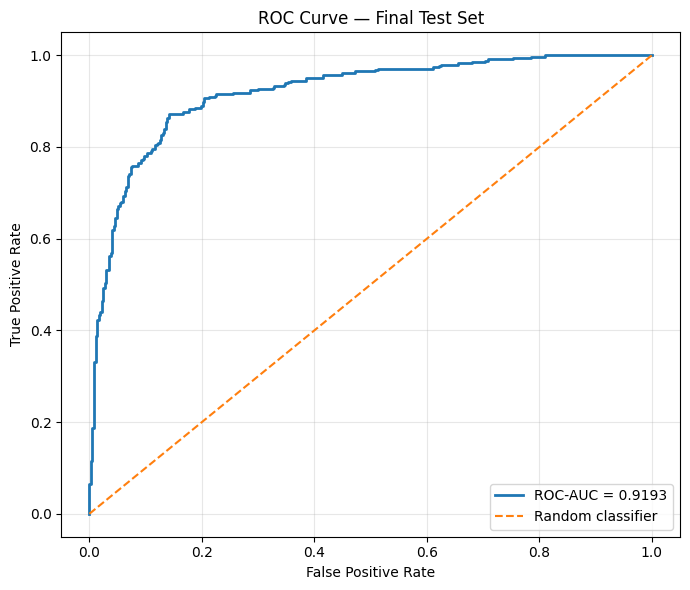

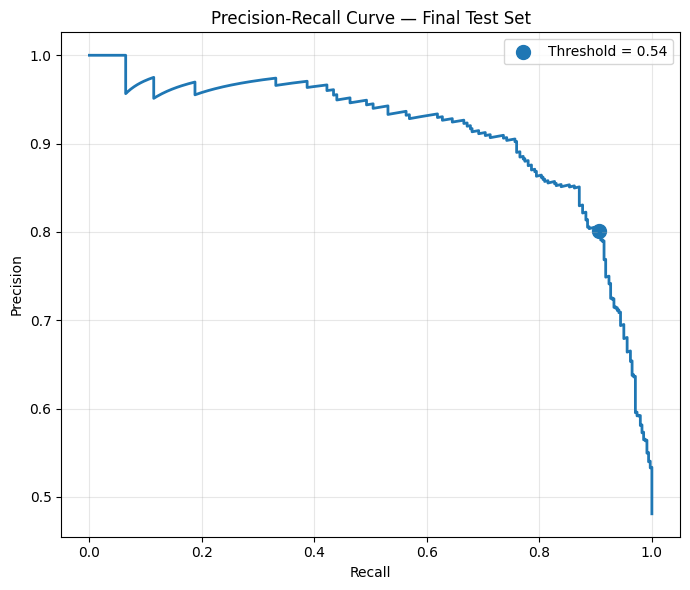

Confusion Matrix:
[[291  77]
 [ 32 309]]


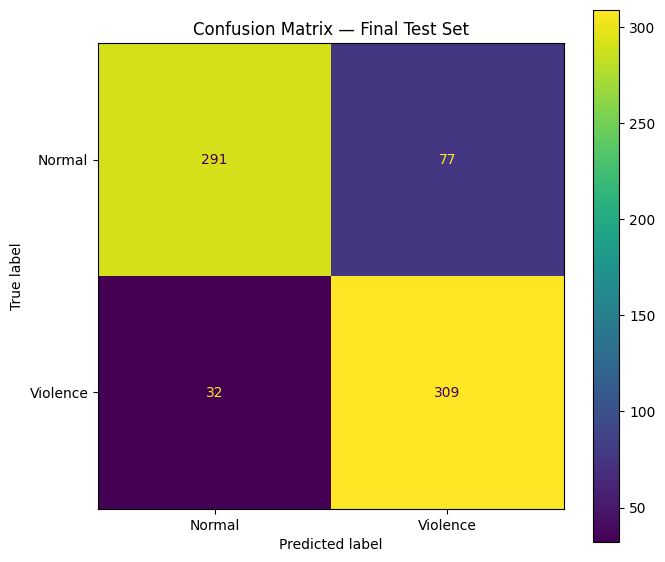


FINAL TEST VISUALIZATION SUMMARY
ROC-AUC             : 0.9193
Locked Threshold    : 0.54
Precision @ 0.54    : 0.8005
Recall @ 0.54     : 0.9062

Confusion Matrix:
[[291  77]
 [ 32 309]]

True Negatives      : 291
False Positives     : 77
False Negatives     : 32
True Positives      : 309


In [65]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ============================================================
# FINAL TEST VISUALIZATIONS
# ============================================================

# ------------------------------------------------------------
# 1. ROC CURVE
# ------------------------------------------------------------

fpr, tpr, roc_thresholds = roc_curve(
    test_targets,
    test_probs
)

roc_auc = roc_auc_score(
    test_targets,
    test_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"ROC-AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Final Test Set")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 2. PRECISION-RECALL CURVE
# ------------------------------------------------------------

precision, recall, pr_thresholds = precision_recall_curve(
    test_targets,
    test_probs
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    linewidth=2
)

# Mark our LOCKED threshold = 0.54
locked_threshold = 0.54

locked_preds = (
    test_probs >= locked_threshold
).astype(int)

# Calculate precision and recall specifically at 0.54
from sklearn.metrics import precision_score, recall_score

locked_precision = precision_score(
    test_targets,
    locked_preds,
    zero_division=0
)

locked_recall = recall_score(
    test_targets,
    locked_preds,
    zero_division=0
)

plt.scatter(
    locked_recall,
    locked_precision,
    s=100,
    label=f"Threshold = {locked_threshold}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Final Test Set")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 3. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    test_targets,
    test_preds
)

print("Confusion Matrix:")
print(cm)

fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Violence"]
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=True
)

ax.set_title(
    "Confusion Matrix — Final Test Set"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. PRINT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FINAL TEST VISUALIZATION SUMMARY")
print("=" * 55)

print(f"ROC-AUC             : {roc_auc:.4f}")
print(f"Locked Threshold    : {locked_threshold:.2f}")
print(f"Precision @ 0.54    : {locked_precision:.4f}")
print(f"Recall @ 0.54     : {locked_recall:.4f}")

print("\nConfusion Matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print(f"\nTrue Negatives      : {tn}")
print(f"False Positives     : {fp}")
print(f"False Negatives     : {fn}")
print(f"True Positives      : {tp}")

In [54]:
# ============================================================
# COMPLETE TEST ERROR ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

# Start from the source-level test dataframe
error_df = test_final.reset_index(drop=True).copy()

# Attach model outputs
error_df["probability"] = test_probs
error_df["prediction"] = test_preds
error_df["actual"] = test_targets

# Human-readable labels
error_df["actual_name"] = error_df["actual"].map({
    0: "Normal",
    1: "Violence"
})

error_df["prediction_name"] = error_df["prediction"].map({
    0: "Normal",
    1: "Violence"
})

# Classify every prediction
error_df["error_type"] = "Correct"

error_df.loc[
    (error_df["actual"] == 0) &
    (error_df["prediction"] == 1),
    "error_type"
] = "False Positive"

error_df.loc[
    (error_df["actual"] == 1) &
    (error_df["prediction"] == 0),
    "error_type"
] = "False Negative"


# ============================================================
# SUMMARY
# ============================================================

print("=" * 60)
print("TEST ERROR ANALYSIS")
print("=" * 60)

print(f"Total samples      : {len(error_df)}")
print(f"Correct predictions: {(error_df['error_type'] == 'Correct').sum()}")
print(f"False positives    : {(error_df['error_type'] == 'False Positive').sum()}")
print(f"False negatives    : {(error_df['error_type'] == 'False Negative').sum()}")


# ============================================================
# FALSE POSITIVES
# ============================================================

false_positives = (
    error_df[
        error_df["error_type"] == "False Positive"
    ]
    .sort_values("probability", ascending=False)
)

print("\n" + "=" * 60)
print("TOP 15 FALSE POSITIVES")
print("=" * 60)

display(
    false_positives[
        [
            "path",
            "class",
            "source_id",
            "probability",
            "actual_name",
            "prediction_name"
        ]
    ].head(15)
)


# ============================================================
# FALSE NEGATIVES
# ============================================================

false_negatives = (
    error_df[
        error_df["error_type"] == "False Negative"
    ]
    .sort_values("probability", ascending=True)
)

print("\n" + "=" * 60)
print("TOP 15 FALSE NEGATIVES")
print("=" * 60)

display(
    false_negatives[
        [
            "path",
            "class",
            "source_id",
            "probability",
            "actual_name",
            "prediction_name"
        ]
    ].head(15)
)


# ============================================================
# SAVE ERROR TABLE
# ============================================================

error_df.to_csv(
    "/kaggle/working/test_error_analysis.csv",
    index=False
)

print("\nSaved:")
print("/kaggle/working/test_error_analysis.csv")

TEST ERROR ANALYSIS
Total samples      : 709
Correct predictions: 600
False positives    : 77
False negatives    : 32

TOP 15 FALSE POSITIVES


,path,class,source_id,probability,actual_name,prediction_name
193,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_Deadpool.2.2018,0.964899,Normal,Violence
252,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=xj64iI5W6r8,0.958596,Normal,Violence
290,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_Thelma...Louise.1991,0.947594,Normal,Violence
167,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_Deadpool.2.2018,0.925110,Normal,Violence
442,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=o4nYn7t1zns,0.917339,Normal,Violence
229,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=fnN_FCj-MTA,0.912682,Normal,Violence
307,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_v=n2lE5MzjmV8,0.909273,Normal,Violence
635,/kaggle/input/datasets/bypktt/xd-violence/test...,Normal,Normal_v=1EvRIhdsX1s,0.907668,Normal,Violence
476,/kaggle/input/datasets/bypktt/xd-violence/trai...,Normal,Normal_Bullet.in.the.Head.1990,0.903052,Normal,Violence
634,/kaggle/input/datasets/bypktt/xd-violence/test...,Normal,Normal_Thelma...Louise.1991,0.893442,Normal,Violence



TOP 15 FALSE NEGATIVES


,path,class,source_id,probability,actual_name,prediction_name
704,/kaggle/input/datasets/bypktt/xd-violence/test...,Shooting,Shooting_Operation.Red.Sea.2018,0.043202,Violence,Normal
102,/kaggle/input/datasets/bypktt/xd-violence/trai...,Explosion,Explosion_v=3wCWpu0HJ_4,0.048950,Violence,Normal
497,/kaggle/input/datasets/bypktt/xd-violence/trai...,Riot,Riot_v=Z1h1h8WmP0E,0.057775,Violence,Normal
508,/kaggle/input/datasets/bypktt/xd-violence/trai...,Riot,Riot_v=QVDtmAb68KM,0.078307,Violence,Normal
135,/kaggle/input/datasets/bypktt/xd-violence/trai...,Fighting,Fighting_Bullet.in.the.Head.1990,0.078802,Violence,Normal
609,/kaggle/input/datasets/bypktt/xd-violence/test...,Explosion,Explosion_v=V7FtjJStY1M,0.088007,Violence,Normal
129,/kaggle/input/datasets/bypktt/xd-violence/trai...,Fighting,Fighting_v=ad1blksyhyM,0.096490,Violence,Normal
522,/kaggle/input/datasets/bypktt/xd-violence/trai...,Riot,Riot_v=nRWweMDjnKo,0.108049,Violence,Normal
133,/kaggle/input/datasets/bypktt/xd-violence/trai...,Fighting,Fighting_v=_Z_ijjCZnBg,0.110064,Violence,Normal
692,/kaggle/input/datasets/bypktt/xd-violence/test...,Riot,Riot_v=BXR3d22BhHs,0.118582,Violence,Normal



Saved:
/kaggle/working/test_error_analysis.csv


In [55]:
# calculates how often each class is correctly detected as violence.
class_results = []

for cls in sorted(test_final["class"].unique()):

    mask = (
        test_final["class"].values == cls
    )

    y_true_cls = test_targets[mask]
    y_pred_cls = test_preds[mask]
    probs_cls = test_probs[mask]

    class_results.append({
        "class": cls,
        "samples": len(y_true_cls),
        "actual_violence": int(y_true_cls.sum()),
        "predicted_violence": int(y_pred_cls.sum()),
        "recall": (
            (y_pred_cls[y_true_cls == 1] == 1).mean()
            if (y_true_cls == 1).sum() > 0
            else np.nan
        )
    })

class_results = pd.DataFrame(class_results)

display(
    class_results.sort_values(
        "recall"
    )
)

,class,samples,actual_violence,predicted_violence,recall
2,Fighting,76,76,63,0.828947
1,Explosion,48,48,42,0.875000
4,Riot,73,73,65,0.890411
5,Shooting,65,65,61,0.938462
0,CarAccident,79,79,78,0.987342
3,Normal,368,0,77,NaN


In [56]:
print(type(frames))
print(type(frames[0]))
print(frames[0].shape)
print(frames[0].dtype)

<class 'torch.Tensor'>
<class 'torch.Tensor'>
torch.Size([3, 224, 224])
torch.float32


Sliding-window inference:   0%|          | 0/113 [00:00<?, ?it/s]


Number of windows: 113
Maximum violence probability: 0.9624456763267517
Maximum probability time: 1.04 seconds


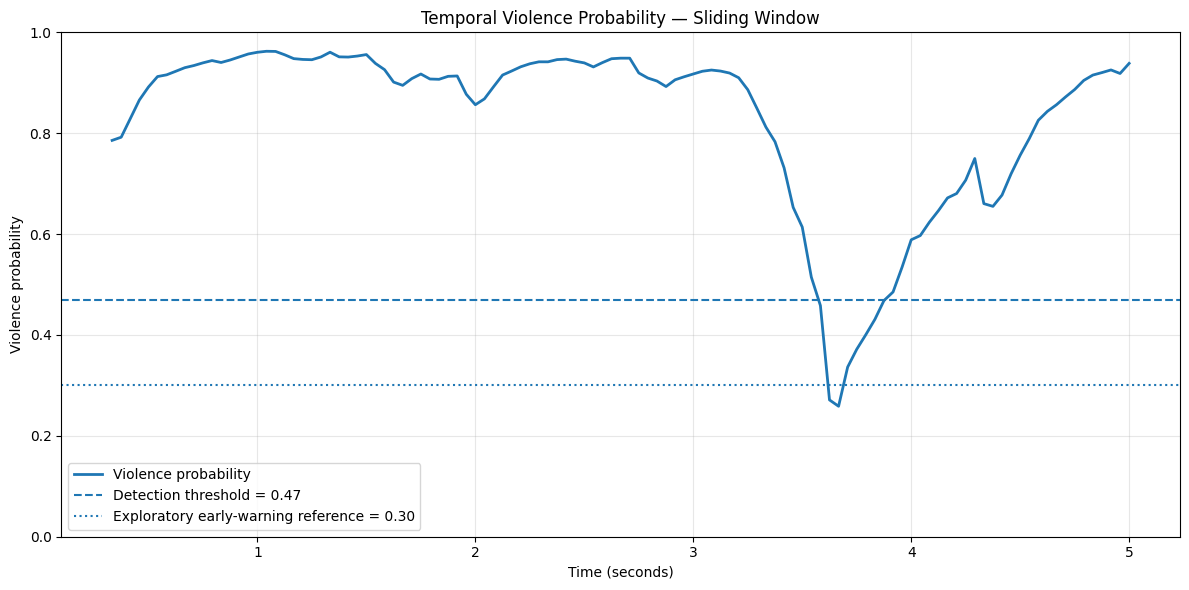

In [57]:
# ============================================================
# SLIDING WINDOW INFERENCE
# ============================================================

NUM_FRAMES = 16
STRIDE = 1

window_times = []
window_probs = []

model.eval()
feature_extractor.eval()

with torch.no_grad():

    for start in tqdm(
        range(
            0,
            len(frames) - NUM_FRAMES + 1,
            STRIDE
        ),
        desc="Sliding-window inference"
    ):

        # ----------------------------------------------------
        # Get 16-frame window
        # ----------------------------------------------------

        window = frames[start:start + NUM_FRAMES]

        # frames is already a Tensor
        # [16, 3, 224, 224]
        frame_tensors = window.to(
            device,
            non_blocking=True
        )

        # ----------------------------------------------------
        # Frozen ResNet18
        # ----------------------------------------------------

        features = feature_extractor(frame_tensors)

        # [16, 512, 1, 1] → [16, 512]
        if features.dim() == 4:
            features = features.squeeze(-1).squeeze(-1)

        # [16, 512] → [1, 16, 512]
        features = features.unsqueeze(0)

        # ----------------------------------------------------
        # GRU classifier
        # ----------------------------------------------------

        logits = model(features)

        probability = torch.sigmoid(logits).item()

        # ----------------------------------------------------
        # Window center time
        # ----------------------------------------------------

        center_frame = start + NUM_FRAMES // 2

        center_time = (
            center_frame / fps
            if fps > 0
            else center_frame
        )

        window_times.append(center_time)
        window_probs.append(probability)


# ============================================================
# CONVERT TO NUMPY
# ============================================================

window_times = np.array(window_times)
window_probs = np.array(window_probs)

print("\nNumber of windows:", len(window_probs))

print(
    "Maximum violence probability:",
    window_probs.max()
)

max_idx = np.argmax(window_probs)

print(
    "Maximum probability time:",
    f"{window_times[max_idx]:.2f} seconds"
)


# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(12, 6))

plt.plot(
    window_times,
    window_probs,
    linewidth=2,
    label="Violence probability"
)

plt.axhline(
    0.47,
    linestyle="--",
    linewidth=1.5,
    label="Detection threshold = 0.47"
)

plt.axhline(
    0.30,
    linestyle=":",
    linewidth=1.5,
    label="Exploratory early-warning reference = 0.30"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Violence probability")

plt.title(
    "Temporal Violence Probability — Sliding Window"
)

plt.ylim(0, 1)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [58]:
# Runs the trained temporal classifier on the validation feature cache 
 # and stores the predicted probabilities and true labels.

import numpy as np
import pandas as pd
import torch

model.eval()

val_cached_probs = []
val_cached_targets = []

with torch.no_grad():

    for features, labels in val_feature_loader:

        features = features.to(
            device,
            non_blocking=True
        )

        logits = model(features)

        probs = torch.sigmoid(logits)

        val_cached_probs.extend(
            probs.cpu().numpy()
        )

        val_cached_targets.extend(
            labels.numpy()
        )

val_cached_probs = np.array(
    val_cached_probs
)

val_cached_targets = np.array(
    val_cached_targets
)

print("Probabilities:", val_cached_probs.shape)
print("Targets:", val_cached_targets.shape)

Probabilities: (608,)
Targets: (608,)


In [59]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(
    0.20,
    0.91,
    0.05
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_cached_probs >= threshold
    ).astype(int)

    threshold_results.append({
        "threshold": threshold,

        "accuracy": accuracy_score(
            val_cached_targets,
            predictions
        ),

        "precision": precision_score(
            val_cached_targets,
            predictions,
            zero_division=0
        ),

        "recall": recall_score(
            val_cached_targets,
            predictions,
            zero_division=0
        ),

        "f1": f1_score(
            val_cached_targets,
            predictions,
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(threshold_df)

,threshold,accuracy,precision,recall,f1
0,0.20,0.746711,0.669789,0.956522,0.787879
1,0.25,0.771382,0.697044,0.946488,0.802837
2,0.30,0.789474,0.718670,0.939799,0.814493
3,0.35,0.799342,0.733509,0.929766,0.820059
4,0.40,0.812500,0.752044,0.923077,0.828829
5,0.45,0.812500,0.760563,0.903010,0.825688
6,0.50,0.817434,0.773256,0.889632,0.827372
7,0.55,0.827303,0.793939,0.876254,0.833068
8,0.60,0.828947,0.807571,0.856187,0.831169
9,0.65,0.832237,0.816720,0.849498,0.832787


In [60]:
# generate temporal probability trajectories → test escalation
import numpy as np
import torch
from tqdm.auto import tqdm

model.eval()

test_trajectories = []

with torch.no_grad():

    for i in tqdm(
        range(len(test_features)),
        desc="Test temporal trajectories"
    ):

        # One video
        x = test_features[i:i+1].to(device)

        trajectory = []

        # Use progressively more of the 16 temporal positions
        for t in range(1, 17):

            prefix = x[:, :t, :]

            logits = model(prefix)

            probability = torch.sigmoid(logits).item()

            trajectory.append(probability)

        test_trajectories.append(trajectory)


test_trajectories = np.array(test_trajectories)

print("Test trajectories shape:", test_trajectories.shape)

Test temporal trajectories:   0%|          | 0/709 [00:00<?, ?it/s]

Test trajectories shape: (709, 16)


In [61]:
# ============================================================
# WHEN DOES THE MODEL CROSS THE VIOLENCE THRESHOLD?
# ============================================================

import numpy as np
import pandas as pd

THRESHOLD = 0.54

# test_trajectories shape should be (709, 16)
print("Trajectory shape:", test_trajectories.shape)

# ------------------------------------------------------------
# Find first timestep where probability >= threshold
# ------------------------------------------------------------

crossing_step = []

for trajectory in test_trajectories:

    crossed = np.where(trajectory >= THRESHOLD)[0]

    if len(crossed) == 0:
        crossing_step.append(np.nan)
    else:
        # +1 because Python index 0 = temporal step 1
        crossing_step.append(crossed[0] + 1)

crossing_step = np.array(crossing_step)

# ------------------------------------------------------------
# Build analysis dataframe
# ------------------------------------------------------------

crossing_df = pd.DataFrame({
    "label": test_labels,
    "crossing_step": crossing_step
})

crossing_df["crossing_fraction"] = (
    crossing_df["crossing_step"] / 16
)

crossing_df["crossing_percent"] = (
    crossing_df["crossing_fraction"] * 100
)

# ------------------------------------------------------------
# Overall results
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("OVERALL THRESHOLD CROSSING")
print("=" * 60)

print(
    "Videos crossing threshold:",
    crossing_df["crossing_step"].notna().sum(),
    "/",
    len(crossing_df)
)

print(
    "Videos never crossing:",
    crossing_df["crossing_step"].isna().sum()
)

print("\nCrossing-step distribution:")
print(
    crossing_df["crossing_step"]
    .value_counts()
    .sort_index()
)

# ------------------------------------------------------------
# Violence
# ------------------------------------------------------------

violence_cross = crossing_df[
    crossing_df["label"] == 1
]

print("\n" + "=" * 60)
print("VIOLENCE")
print("=" * 60)

print("Total:", len(violence_cross))

print(
    "Crossed:",
    violence_cross["crossing_step"].notna().sum()
)

print(
    "Never crossed:",
    violence_cross["crossing_step"].isna().sum()
)

print("\nCrossing step statistics:")
print(
    violence_cross["crossing_step"].describe()
)

print("\nCrossing percentage of video:")
print(
    violence_cross["crossing_percent"].describe()
)

# ------------------------------------------------------------
# Normal
# ------------------------------------------------------------

normal_cross = crossing_df[
    crossing_df["label"] == 0
]

print("\n" + "=" * 60)
print("NORMAL")
print("=" * 60)

print("Total:", len(normal_cross))

print(
    "Crossed:",
    normal_cross["crossing_step"].notna().sum()
)

print(
    "Never crossed:",
    normal_cross["crossing_step"].isna().sum()
)

print("\nCrossing step statistics:")
print(
    normal_cross["crossing_step"].describe()
)

print("\nCrossing percentage of video:")
print(
    normal_cross["crossing_percent"].describe()
)

Trajectory shape: (709, 16)

OVERALL THRESHOLD CROSSING
Videos crossing threshold: 473 / 709
Videos never crossing: 236

Crossing-step distribution:
crossing_step
1.0     254
2.0      66
3.0      37
4.0      30
5.0      18
6.0      13
7.0       9
8.0      11
9.0       5
10.0      3
11.0      5
12.0      6
13.0      7
14.0      2
15.0      5
16.0      2
Name: count, dtype: int64

VIOLENCE
Total: 341
Crossed: 319
Never crossed: 22

Crossing step statistics:
count    319.000000
mean       2.836991
std        3.186806
min        1.000000
25%        1.000000
50%        1.000000
75%        3.000000
max       16.000000
Name: crossing_step, dtype: float64

Crossing percentage of video:
count    319.000000
mean      17.731191
std       19.917539
min        6.250000
25%        6.250000
50%        6.250000
75%       18.750000
max      100.000000
Name: crossing_percent, dtype: float64

NORMAL
Total: 368
Crossed: 154
Never crossed: 214

Crossing step statistics:
count    154.000000
mean       2.980

In [62]:
print("model_test:", len(model_test))
print("test_trajectories:", len(test_trajectories))

print(model_test[["path", "class", "label"]].head())

model_test: 709
test_trajectories: 709
                                                 path        class  label
12  /kaggle/input/datasets/bypktt/xd-violence/trai...  CarAccident      1
13  /kaggle/input/datasets/bypktt/xd-violence/trai...  CarAccident      1
14  /kaggle/input/datasets/bypktt/xd-violence/trai...  CarAccident      1
15  /kaggle/input/datasets/bypktt/xd-violence/trai...  CarAccident      1
19  /kaggle/input/datasets/bypktt/xd-violence/trai...  CarAccident      1


STRICTLY ESCALATING VIOLENCE TRAJECTORY ANALYSIS
Total test videos:                    709
Violence videos:                      341
Strictly escalating videos:           66
Strictly escalating violence videos:  64
Trajectory shape:                     (64, 16)

TEMPORAL TRAJECTORY SUMMARY
 Step  Mean Probability  Median Probability  Above Threshold (%)  Below Threshold (%)
    1            0.5751              0.5858              73.4375              26.5625
    2            0.6426              0.6439              85.9375              14.0625
    3            0.7059              0.7172              95.3125               4.6875
    4            0.7525              0.7688             100.0000               0.0000
    5            0.7879              0.8025             100.0000               0.0000
    6            0.8162              0.8258             100.0000               0.0000
    7            0.8415              0.8434             100.0000               0.0000
    8            0.86

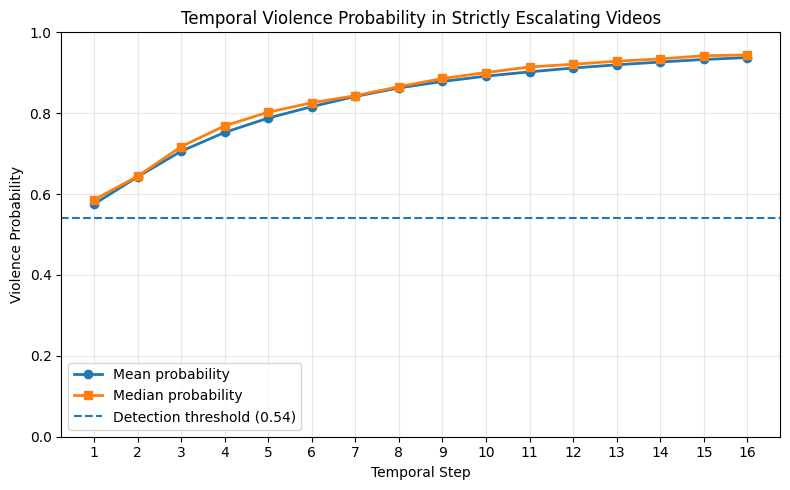


FILES SAVED
strict_escalation_trajectory_summary.csv
strict_escalation_trajectory.png
strict_escalating_violence_videos.csv


In [63]:
# ============================================================
# STRICTLY ESCALATING VIOLENCE TRAJECTORY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

THRESHOLD = 0.54

# ------------------------------------------------------------
# ALIGN TEST DATA WITH TRAJECTORIES
# ------------------------------------------------------------

test_df = model_test.reset_index(drop=True).copy()

assert len(test_df) == len(test_trajectories), (
    f"Mismatch: model_test has {len(test_df)} rows, "
    f"but test_trajectories has {len(test_trajectories)} trajectories."
)

# ------------------------------------------------------------
# STRICT ESCALATION
# Every probability must be strictly greater than
# the previous temporal step
# P1 < P2 < P3 < ... < P16
# ------------------------------------------------------------

strict_escalation = np.all(
    np.diff(test_trajectories, axis=1) > 0,
    axis=1
)

test_df["strict_escalation"] = strict_escalation

# ------------------------------------------------------------
# SELECT ACTUAL VIOLENCE + STRICTLY ESCALATING VIDEOS
# ------------------------------------------------------------

violence_mask = (
    test_df["label"].values == 1
)

strict_violence_mask = (
    violence_mask &
    strict_escalation
)

violence_trajectories = test_trajectories[
    strict_violence_mask
]

# ------------------------------------------------------------
# BASIC RESULTS
# ------------------------------------------------------------

print("=" * 70)
print("STRICTLY ESCALATING VIOLENCE TRAJECTORY ANALYSIS")
print("=" * 70)

print(f"Total test videos:                    {len(test_df)}")
print(f"Violence videos:                      {violence_mask.sum()}")
print(f"Strictly escalating videos:           {strict_escalation.sum()}")
print(
    f"Strictly escalating violence videos:  "
    f"{strict_violence_mask.sum()}"
)

print(
    f"Trajectory shape:                     "
    f"{violence_trajectories.shape}"
)

# ------------------------------------------------------------
# HANDLE CASE WHERE NO TRAJECTORIES ARE FOUND
# ------------------------------------------------------------

if len(violence_trajectories) == 0:

    print("\nNo strictly escalating violence trajectories found.")
    print("Try relaxing the escalation definition if required.")

else:

    # --------------------------------------------------------
    # MEAN / MEDIAN TRAJECTORY
    # --------------------------------------------------------

    mean_trajectory = violence_trajectories.mean(axis=0)

    median_trajectory = np.median(
        violence_trajectories,
        axis=0
    )

    # --------------------------------------------------------
    # THRESHOLD STATISTICS
    # --------------------------------------------------------

    above_threshold = (
        violence_trajectories >= THRESHOLD
    ).mean(axis=0) * 100

    below_threshold = (
        violence_trajectories < THRESHOLD
    ).mean(axis=0) * 100

    # --------------------------------------------------------
    # FIRST THRESHOLD CROSSING
    # --------------------------------------------------------

    crossing_steps = []

    for trajectory in violence_trajectories:

        crossed = np.where(
            trajectory >= THRESHOLD
        )[0]

        if len(crossed) > 0:
            crossing_steps.append(crossed[0] + 1)

    if len(crossing_steps) > 0:
        mean_crossing_step = np.mean(crossing_steps)
        median_crossing_step = np.median(crossing_steps)
    else:
        mean_crossing_step = np.nan
        median_crossing_step = np.nan

    # --------------------------------------------------------
    # SUMMARY TABLE
    # --------------------------------------------------------

    trajectory_summary = pd.DataFrame({
        "Step": np.arange(1, 17),
        "Mean Probability": mean_trajectory,
        "Median Probability": median_trajectory,
        "Above Threshold (%)": above_threshold,
        "Below Threshold (%)": below_threshold
    })

    print("\n" + "=" * 70)
    print("TEMPORAL TRAJECTORY SUMMARY")
    print("=" * 70)

    print(
        trajectory_summary.to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

    # --------------------------------------------------------
    # THRESHOLD CROSSING RESULTS
    # --------------------------------------------------------

    print("\n" + "=" * 70)
    print("THRESHOLD CROSSING")
    print("=" * 70)

    print(f"Threshold:                 {THRESHOLD}")

    if len(crossing_steps) > 0:

        print(
            f"Videos crossing threshold: "
            f"{len(crossing_steps)} / "
            f"{len(violence_trajectories)}"
        )

        print(
            f"Mean crossing step:        "
            f"{mean_crossing_step:.2f}"
        )

        print(
            f"Median crossing step:      "
            f"{median_crossing_step:.2f}"
        )

    else:

        print("No trajectory crossed the threshold.")

    # --------------------------------------------------------
    # SAVE SUMMARY TABLE
    # --------------------------------------------------------

    trajectory_summary.to_csv(
        "strict_escalation_trajectory_summary.csv",
        index=False
    )

    # --------------------------------------------------------
    # PAPER-READY PLOT
    # --------------------------------------------------------

    steps = np.arange(1, 17)

    plt.figure(figsize=(8, 5))

    plt.plot(
        steps,
        mean_trajectory,
        marker="o",
        linewidth=2,
        label="Mean probability"
    )

    plt.plot(
        steps,
        median_trajectory,
        marker="s",
        linewidth=2,
        label="Median probability"
    )

    plt.axhline(
        THRESHOLD,
        linestyle="--",
        linewidth=1.5,
        label=f"Detection threshold ({THRESHOLD})"
    )

    plt.xlabel("Temporal Step")
    plt.ylabel("Violence Probability")

    plt.title(
        "Temporal Violence Probability in Strictly Escalating Videos"
    )

    plt.xticks(steps)
    plt.ylim(0, 1)

    plt.grid(
        True,
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        "strict_escalation_trajectory.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # --------------------------------------------------------
    # SAVE SELECTED VIDEO INFORMATION
    # --------------------------------------------------------

    selected_videos = test_df[
        strict_violence_mask
    ].copy()

    selected_videos.to_csv(
        "strict_escalating_violence_videos.csv",
        index=False
    )

    print("\n" + "=" * 70)
    print("FILES SAVED")
    print("=" * 70)

    print("strict_escalation_trajectory_summary.csv")
    print("strict_escalation_trajectory.png")
    print("strict_escalating_violence_videos.csv")

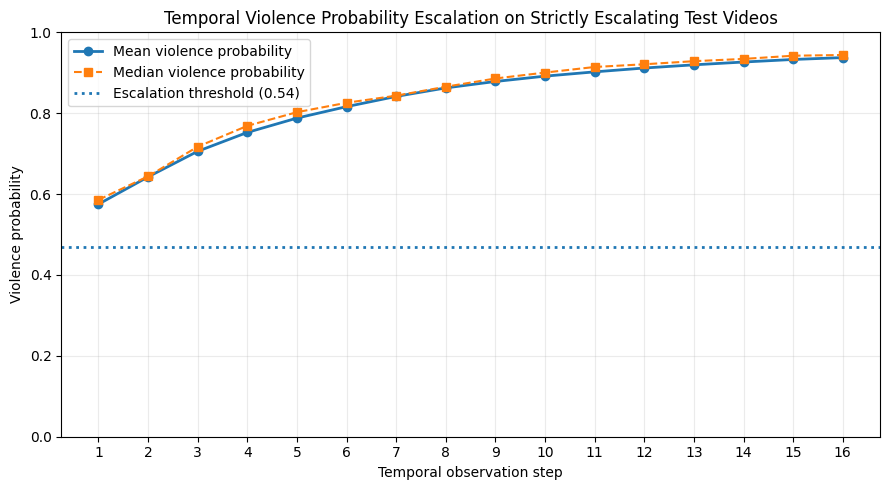

In [64]:
import numpy as np
import matplotlib.pyplot as plt

# Existing trajectories for the 73 strict-escalating violence videos
mean_trajectory = violence_trajectories.mean(axis=0)
median_trajectory = np.median(violence_trajectories, axis=0)

steps = np.arange(1, 17)

plt.figure(figsize=(9, 5))

plt.plot(
    steps,
    mean_trajectory,
    marker="o",
    linewidth=2,
    label="Mean violence probability"
)

plt.plot(
    steps,
    median_trajectory,
    marker="s",
    linestyle="--",
    linewidth=1.5,
    label="Median violence probability"
)

plt.axhline(
    y=0.47,
    linestyle=":",
    linewidth=2,
    label="Escalation threshold (0.54)"
)

plt.xlabel("Temporal observation step")
plt.ylabel("Violence probability")
plt.title(
    "Temporal Violence Probability Escalation "
    "on Strictly Escalating Test Videos"
)

plt.xticks(steps)
plt.ylim(0, 1)
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()

plt.savefig(
    "temporal_escalation_test_set.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()